# Parametric studies

This notebook runs a few hundred cases: `ga.sweep` for a regular grid of values, `ga.run_many` for
everything else, and a few ways of drawing the results that serve a design decision better than a
table.

It uses the office building of the [first notebook](01_simulation.ipynb) and the Sizing tool of the
[second](02_sizing.ipynb). The figures keep the colours of the application. Where a colour stands
for a quantity and not a mode, it is the contour's ramp, blue for low values and red for high ones,
the one the thermal contour uses.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as effects

import pyghe as ga
import ghestyle as ghe
from demo_project import make_project

ghe.use()          # the colours, fonts and axis style of GHE Analysis
p = make_project()
installed = 12 * p.ground_heat_exchanger.active_length

## A sweep, in one call

`sweep` takes a project, a dictionary of the parameters to vary and a command. It builds every
combination, runs them in parallel on copies of the project and returns a table with one row per
case. Parameters are named by their path in the project, the same names used to set them.

Here is the ground conductivity against the antifreeze concentration, sizing each case:

In [2]:
conductivity = np.linspace(1.5, 3.5, 9)
antifreeze = [10, 20, 30, 40]
study = ga.sweep(p, {"ground_heat_exchanger.ground_thermal_conductivity": conductivity,
                     "heat_carrier_fluid.antifreeze_mass_concentration": antifreeze}, "size")
print(len(study), "cases")
study[["ground_heat_exchanger.ground_thermal_conductivity", "heat_carrier_fluid.antifreeze_mass_concentration",
       "governing_total_borehole_length", "status"]].head(6).round(1)

36 cases


,ground_heat_exchanger.ground_thermal_conductivity,heat_carrier_fluid.antifreeze_mass_concentration,governing_total_borehole_length,status
0,1.5,10,1208.5,ok
1,1.5,20,1212.5,ok
2,1.5,30,1334.9,ok
3,1.5,40,1380.2,ok
4,1.8,10,1145.1,ok
5,1.8,20,1149.4,ok


Thirty-six cases are hard to read in a table. A family of curves works better: one line per
concentration, coloured from blue (the least antifreeze) to red (the most) in the contour's ramp, so
that the order of the lines is also the order of the colours.

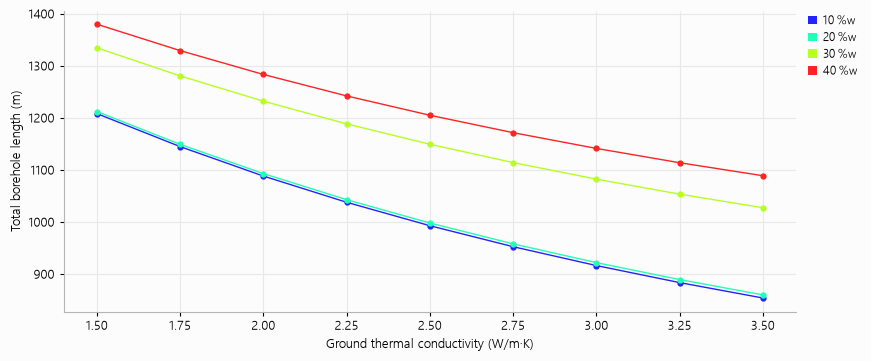

In [3]:
colours = ghe.hue_colours(len(antifreeze))
column = "governing_total_borehole_length"
lam = "ground_heat_exchanger.ground_thermal_conductivity"
conc = "heat_carrier_fluid.antifreeze_mass_concentration"

fig, ax = ghe.figure(8.6, 3.5)
for colour, value in zip(colours, antifreeze):
    rows = study[study[conc] == value]
    ax.plot(rows[lam], rows[column], color=colour, marker="o", markersize=3.5)
ghe.axis_titles(ax, x="Ground thermal conductivity (W/m·K)", y="Total borehole length (m)")
ghe.legend(ax, [(c, f"{v} %w") for c, v in zip(colours, antifreeze)])

The length falls as the conductivity rises. The antifreeze matters more than one might expect:
10 and 20 %w give nearly the same length, 30 %w adds 10 to 16 % and 40 %w 14 to 21 %.
Ranking parameters this way is the main use of a sweep.

### A case that fails

A sweep does not stop on a bad case. If one of the values is not physical, its row is marked as
failed, with the reason, and the others carry on.

In [4]:
table = ga.sweep(p, {"heat_carrier_fluid.antifreeze_mass_concentration": [10, 25, 70]}, "size")
table[["heat_carrier_fluid.antifreeze_mass_concentration", "governing_total_borehole_length", "status", "error"]]

,heat_carrier_fluid.antifreeze_mass_concentration,governing_total_borehole_length,status,error
0,10,993.134140,ok,NaN
1,25,1013.253464,ok,NaN
2,70,NaN,failed,HeatCarrierFluid.antifreeze_mass_concentration...


## A map of two parameters

Two parameters give a surface. This map asks how long the field must be for a ground conductivity
(across) and a change in the building's loads (up). The loads are not a parameter of the project
but a series, so I build the variants by hand and hand them to `run_many`, which runs the same
command on a list of projects and returns the results in the same order.

In [5]:
conductivity = np.linspace(1.5, 3.5, 9)
growth = np.linspace(0.6, 1.4, 9)
loads = p.building_loads

variants = []
for g in growth:
    for k in conductivity:
        q = p.copy()
        q.ground_heat_exchanger.ground_thermal_conductivity = float(k)
        q.building_loads = ga.HourlyBuildingLoadsSeparate(
            cooling_demand=loads.cooling_demand * g, heating_demand=loads.heating_demand * g,
            dhw_demand=loads.dhw_demand)
        variants.append(q)

t0 = time.perf_counter()
results = ga.run_many(variants, "size")
print(f"{len(variants)} sizings in {time.perf_counter() - t0:.0f} s")
length = np.array([r.governing_total_borehole_length for r in results]).reshape(len(growth), len(conductivity))

81 sizings in 5 s


the dashed line is the 1200 m installed in the project


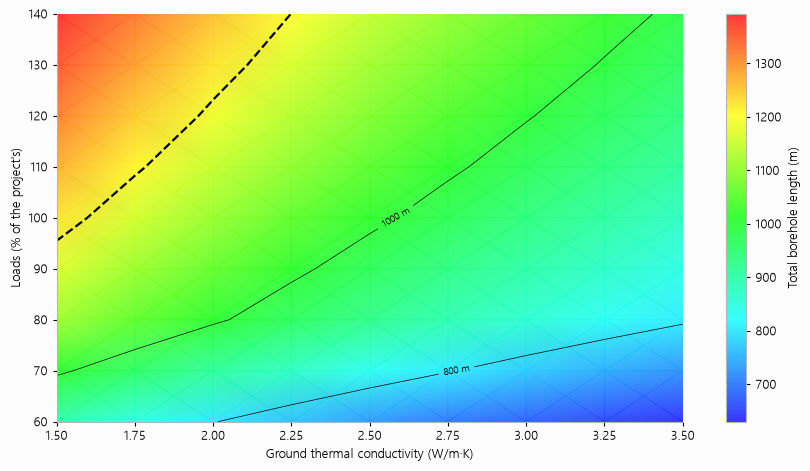

In [6]:
fig, ax = ghe.figure(8.0, 4.6)
mesh = ax.pcolormesh(conductivity, growth * 100, length, cmap=ghe.hue_colormap(), shading="gouraud", alpha=0.9)
rounded = [v for v in np.arange(400, 2000, 200) if abs(v - installed) > 1]
lines = ax.contour(conductivity, growth * 100, length, levels=rounded, colors="black", linewidths=0.5)
ax.clabel(lines, fmt="%d m", fontsize=7)
mine = ax.contour(conductivity, growth * 100, length, levels=[installed], colors="black", linewidths=1.6, linestyles="--")
ghe.axis_titles(ax, x="Ground thermal conductivity (W/m·K)", y="Loads (% of the project's)")
ax.grid(False)
bar = fig.colorbar(mesh, ax=ax, label="Total borehole length (m)")
print(f"the dashed line is the {installed:.0f} m installed in the project")

Red is a long, expensive field and blue a short one. The dashed line is the length the project
actually has: below and to the right of it the field is long enough, above and to the left it is
not. The map shows how far the loads can grow, or the conductivity fall, before the design needs
more boreholes, and how the two compensate each other along the line.

## Does the design pass?

The Sizing tool gives a length. The question a designer eventually asks is the other one: for this
length, does the simulation stay within the limits of the heat pumps? Here is a map of the coldest
entering fluid temperature over 25 years for the spacing between boreholes (across) and the length
of each (up), twelve boreholes throughout. The red line is the heating limit, and the design passes
where the map is on the warm side of it.

In [7]:
spacings = np.arange(4.0, 10.5, 1.0)
lengths = np.arange(80.0, 161.0, 20.0)

variants = []
for length_h in lengths:
    for spacing in spacings:
        q = p.copy()
        q.ground_heat_exchanger.active_length = float(length_h)
        q.ground_heat_exchanger.coordinates = ga.Coordinates.rectangle(nx=4, ny=3, spacing=float(spacing))
        variants.append(q)

t0 = time.perf_counter()
runs = ga.run_many(variants, "simulate")
print(f"{len(variants)} simulations of 25 years in {time.perf_counter() - t0:.0f} s")
coldest = np.array([r.summary.minimum_eft for r in runs]).reshape(len(lengths), len(spacings))
limit = p.heat_pump_performance.temperature_limit.heating

35 simulations of 25 years in 3 s


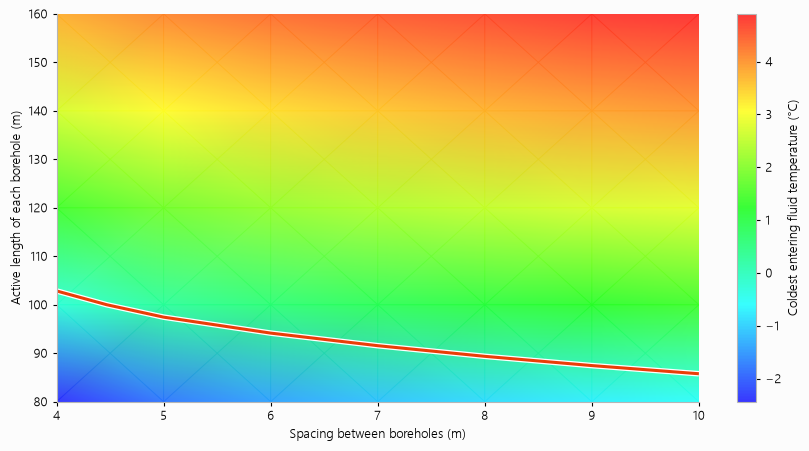

In [8]:
fig, ax = ghe.figure(8.0, 4.4)
mesh = ax.pcolormesh(spacings, lengths, coldest, cmap=ghe.hue_colormap(), shading="gouraud", alpha=0.9)
ax.contour(spacings, lengths, coldest, levels=[limit], colors=ghe.RED, linewidths=2.2,
           path_effects=[effects.withStroke(linewidth=4, foreground="white")])
ax.grid(False)
ghe.axis_titles(ax, x="Spacing between boreholes (m)", y="Active length of each borehole (m)")
bar = fig.colorbar(mesh, ax=ax, label="Coldest entering fluid temperature (°C)")

The red line is the heating limit, 0 °C here. Blue is cold and red is warm, as on the
application's thermal contour. The design passes above the line, where the boreholes are long
enough for their spacing, and fails below it. The line slopes the way one would expect: the closer
the boreholes, the longer each has to be, and the gain from more spacing flattens out towards the
right.

## When the inputs are uncertain

A conductivity measured on site comes with an error, and so does the ground temperature. Instead of
choosing one value, I draw a few hundred from their distributions, size each case and look at the
spread of lengths. The call is `run_many`, on a random list of projects.

The conductivity is log-normal around 2.5 W/m·K with a spread of 12 %, and the mean surface
temperature is normal around 8 °C with a standard deviation of half a degree:

In [9]:
rng = np.random.default_rng(2026)
n = 120
k = 2.5 * np.exp(rng.normal(0, 0.12, n))
t0_ground = rng.normal(8.0, 0.5, n)

variants = []
for conductivity_i, surface_i in zip(k, t0_ground):
    q = p.copy()
    q.ground_heat_exchanger.ground_thermal_conductivity = float(conductivity_i)
    q.ground_heat_exchanger.mean_surface_temperature = float(surface_i)
    variants.append(q)

t0 = time.perf_counter()
sized = np.array([r.governing_total_borehole_length for r in ga.run_many(variants, "size")])
print(f"{n} sizings in {time.perf_counter() - t0:.0f} s")
p10, p50, p90 = np.percentile(sized, [10, 50, 90])
print(f"required length: median {p50:.0f} m, 80 % of cases between {p10:.0f} and {p90:.0f} m")
print(f"the {installed:.0f} m installed are enough in {100 * np.mean(sized <= installed):.0f} % of the cases")

120 sizings in 7 s
required length: median 1010 m, 80 % of cases between 916 and 1097 m
the 1200 m installed are enough in 98 % of the cases


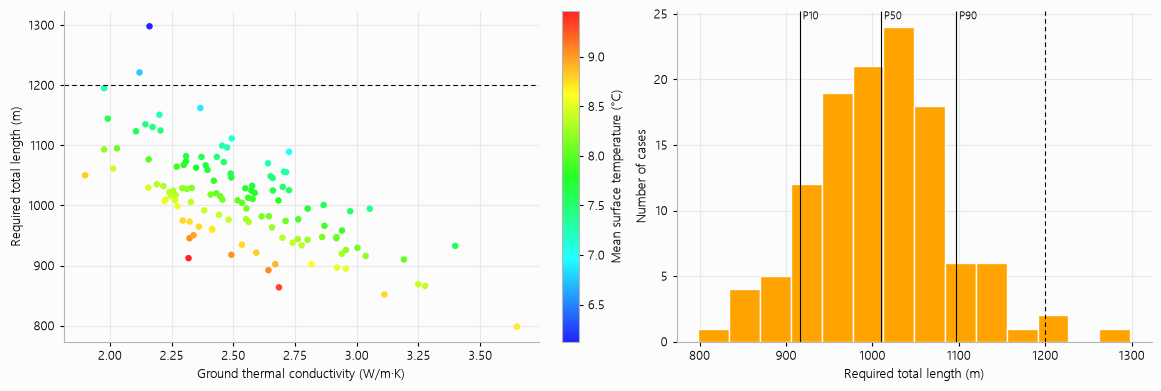

In [10]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 3.8))

mesh = left.scatter(k, sized, c=t0_ground, cmap=ghe.hue_colormap(), s=22, edgecolor="none")
left.axhline(installed, color=ghe.BLACK, linewidth=0.8, linestyle=(0, (4, 3)))
ghe.axis_titles(left, x="Ground thermal conductivity (W/m·K)", y="Required total length (m)")
bar = fig.colorbar(mesh, ax=left, label="Mean surface temperature (°C)")

right.hist(sized, bins=14, color=ghe.ORANGE, edgecolor=ghe.BACKGROUND)
for value, label in ((p10, "P10"), (p50, "P50"), (p90, "P90")):
    right.axvline(value, color=ghe.BLACK, linewidth=0.8)
    right.text(value, right.get_ylim()[1], f" {label}", va="top", fontsize=8)
right.axvline(installed, color=ghe.BLACK, linewidth=0.8, linestyle=(0, (4, 3)))
ghe.axis_titles(right, x="Required total length (m)", y="Number of cases")

On the left, each point is a sizing: length against conductivity, coloured by the surface
temperature in the contour's ramp. The conductivity sets the trend and the temperature moves each
point off it. On the right, the same lengths as a histogram, with the 10th, 50th and 90th
percentiles. The dashed line is the length installed. The figure gives a probability rather than a
length: the margin the installed field has against the uncertainty on the ground.

## Failures in a batch

`sweep` marks a failed row, and `run_many` does the same in its own way. The results come back as a
list in the order of the projects, and a case that fails has an exception in its place instead of a
result. A cross-field mistake, which is only caught when the case is computed, makes a good
example: each value below is acceptable alone, but an outer diameter smaller than the inner one is
not.

In [11]:
bad = p.copy()
bad.borehole_resistance.pipe_outer_diameter = 0.030      # smaller than the inner diameter, 0.033
batch = ga.run_many([p, bad, p], "size")
for i, result in enumerate(batch):
    if isinstance(result, ga.PygheError):
        print(f"case {i}: failed: {result}")
    else:
        print(f"case {i}: {result.governing_total_borehole_length:.0f} m")

case 0: 1013 m
case 1: failed: p.borehole_resistance: pipe_outer_diameter must exceed pipe_inner_diameter
case 2: 1013 m


## How many workers?

A batch runs several servers at once, and you can choose how many workers. More workers are not
always faster: each server holds the kernel's arrays in memory, and it is memory bandwidth, not
arithmetic, that limits a batch. The cell below measures this on the current machine, with
forty-eight sizings and one to eight workers.

In [12]:
variants = []
for conductivity_i in np.linspace(1.5, 3.5, 48):
    q = p.copy()
    q.ground_heat_exchanger.ground_thermal_conductivity = float(conductivity_i)
    variants.append(q)

workers = [1, 2, 4, 8]
seconds = []
for w in workers:
    t0 = time.perf_counter()
    ga.run_many(variants, "size", workers=w)
    seconds.append(time.perf_counter() - t0)
    print(f"{w} workers: {seconds[-1]:.1f} s")

1 workers: 6.7 s


2 workers: 4.2 s


4 workers: 3.4 s


8 workers: 3.6 s


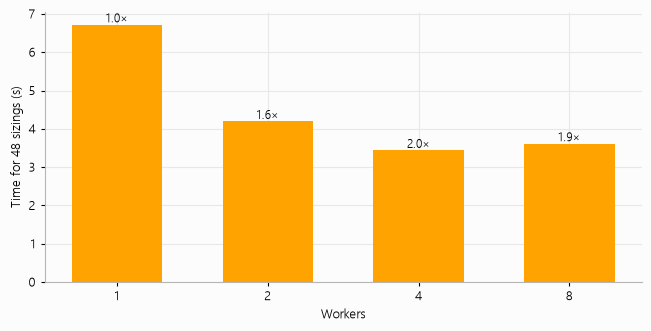

In [13]:
fig, ax = ghe.figure(6.4, 3.2)
ax.bar([str(w) for w in workers], seconds, color=ghe.ORANGE, width=0.6)
for i, s in enumerate(seconds):
    ax.text(i, s, f"{seconds[0] / s:.1f}×", ha="center", va="bottom", fontsize=8.5)
ghe.axis_titles(ax, x="Workers", y="Time for 48 sizings (s)")

The label over each bar is the speed-up over one worker. It levels off early, and past that point
more workers only use more memory, which is why `workers` defaults to about one per physical core
and not one per logical core. The times depend on the machine; the shape of the curve much less.

## Where to go from here

Everything here is built from `sweep`, `run_many` and the results' own arrays. The same pattern
serves for optimisation: a function that takes a few parameters and returns a number is a `copy()`,
an assignment and a `simulate()`, and it can be passed to an optimiser.